# Knowing When to Defer: An Ordinal Evidential Involution–Attention Network for Calibrated Knee Osteoarthritis Grading

## 05 — What causes the deferral behaviour?


| Axis | Levels | Bears on |
|---|---|---|
| A0 backbone | scratch stem · EfficientNet-B0 · DenseNet-121 | grading |
| A1 global branch | none · SE · windowed SA | grading |
| A2 gate | mean · learned · vacuity | both |
| **A3 head** | softmax · flat Dirichlet · **ordinal** | **deferral — the key axis** |
| A4 loss terms | drop $L_{\rm cal}$ · $L_{\rm KL}$ · $L_{\rm mono}$ | calibration |
| A5 operator | conv · involution · EvI | grading (a control) |
| A6 resolution | 160 · 224 · 320 | grading |
| A7 preprocessing | none · histogram eq. · CLAHE | grading |



### Setup

Mount Drive so results survive a disconnect, then load the module.

In [ ]:
# --- Colab bootstrap: run this first in every notebook ---------------------
import os, sys, glob, shutil

IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = True        # True = results survive a disconnect. False = faster, but temporary.

if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = "/content/drive/MyDrive/EvIA_Knee"
elif IN_COLAB:
    PROJECT = "/content/EvIA_Knee"
else:
    PROJECT = os.path.abspath(".")

os.makedirs(PROJECT, exist_ok=True)
sys.path.insert(0, PROJECT)          # so `import evia_knee` finds the module written by 00
CACHE = os.path.join(PROJECT, "cache")
print("project:", PROJECT)

Mounted at /content/drive
project: /content/drive/MyDrive/EvIA_Knee


In [ ]:
import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
print("TF", tf.__version__, "| GPU:", len(gpus))
if not gpus:
    print("  !! No GPU. Runtime > Change runtime type > T4 GPU, then re-run.")

TF 2.21.0 | GPU: 1


In [ ]:
import os, sys, json, time
import numpy as np, pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

import evia_knee as E
assert hasattr(E.Config(), "lr_schedule"), \
    "Old evia_knee.py loaded. Run 00_core, then Runtime > Restart session."
print("evia_knee:", E.__file__, "| lr schedule", E.Config().lr_schedule)
import evia_viz as V                 # figure style, written by notebook 00
V.use()                # written by notebook 00, found via PROJECT on sys.path
from evia_knee import Config

if IN_COLAB and not os.path.isdir("/content/knee"):
    !pip -q install kaggle
    E.download_kaggle("knee", "/content/knee")
root = E.find_dataset("knee")
print("knee data at:", root)
for d in sorted({os.path.dirname(p)
                 for p in glob.glob(root + "/**/*.png", recursive=True)}):
    print(f"  {os.path.basename(d):14s} {len(glob.glob(d + '/*.png')):5d} images")
print("\nKL1 vs KL2 is the boundary that decides definite OA, and the one "
      "readers disagree on most.")

print("task      :", "knee OA, Kellgren-Lawrence grade 0-4")
print("grades    :", E.GRADE_NAMES)
print("decision  : KL >=", E.OA_THRESHOLD, "=", E.OA_NAME)

# One config object drives everything. Changing a field here changes the experiment.
CFG = Config(
    img_size=224,                  # the radiographs are native ~224 px; upsampling adds nothing
    preprocess="clahe",
    backbone="densenet121",        # full ImageNet DenseNet-121 + EvIA side branch
    widths=(256, 320),             # EvIA branch blocks at 14x14 and 7x7
    global_branch="window",        # EvIA-W
    gate="vacuity",                # parameter-free gate
    operator="evi",
    head="ordinal",
    epochs=60,                     # cosine schedule: every run trains exactly 60 epochs
    batch_size=32,                 # 224 px radiographs leave room for a large batch
    seeds=(42, 43, 44, 45, 46),    # set to (42,) for a quick first pass
    out_dir=os.path.join(PROJECT, "results"),
)
os.makedirs(CFG.out_dir, exist_ok=True)
print("results ->", CFG.out_dir)

evia_knee: /content/drive/MyDrive/EvIA_Knee/evia_knee.py | lr schedule cosine
kaggle datasets download -d shashwatwork/knee-osteoarthritis-dataset-with-severity -p /content/knee
unzipping knee-osteoarthritis-dataset-with-severity.zip
registered DATA_ROOTS['knee'] = /content/knee
knee data at: /content/knee
  0                604 images
  1                275 images
  2                403 images
  3                200 images
  4                 44 images
  0                639 images
  1                296 images
  2                447 images
  3                223 images
  4                 51 images
  0               2286 images
  1               1046 images
  2               1516 images
  3                757 images
  4                173 images
  0                328 images
  1                153 images
  2                212 images
  3                106 images
  4                 27 images

KL1 vs KL2 is the boundary that decides definite OA, and the one readers disagree on most.


In [ ]:
ds = E.load_knee(cfg=CFG, seed=42)
idx = ds["idx"]
print(f"{ds['name']}: {len(ds['y'])} images")
print("  grades    :", np.bincount(ds["y"], minlength=5))
print(f"  definite OA : {(ds['y']>=E.OA_THRESHOLD).sum()} "
      f"({(ds['y']>=E.OA_THRESHOLD).mean():.1%})")

# Decoded once into uint8 arrays and cached. A restarted session reloads in seconds.
data = {k: E.cached_split(ds["paths"][idx[k]], ds["y"][idx[k]], CFG, "knee_" + k, CACHE)
        for k in ("train", "val", "test")}
Xte, Yte = data["test"]
print(" ", {k: f"{v[0].shape} {v[0].dtype}" for k, v in data.items()})

  using the dataset's own train/val/test split
Knee OA (KL 0-4): 9786 images
  grades    : [3857 1770 2578 1286  295]
  definite OA : 4159 (42.5%)
  knee_train: loaded from cache
  knee_val: loaded from cache
  knee_test: loaded from cache
  {'train': '(5778, 224, 224, 3) uint8', 'val': '(826, 224, 224, 3) uint8', 'test': '(1656, 224, 224, 3) uint8'}


In [ ]:
AXES = {
 "A0_backbone":  [("scratch", dict(backbone="scratch", widths=(64, 128, 256, 320))),
                  ("EfficientNet-B0", dict(backbone="effb0")),
                  ("DenseNet-121", dict(backbone="densenet121"))],
 "A1_global":    [("none", dict(global_branch="none")),
                  ("SE", dict(global_branch="se")),
                  ("windowed SA", dict(global_branch="window"))],
 "A2_gate":      [("mean 0.5", dict(gate="mean")),
                  ("learned", dict(gate="learned")),
                  ("vacuity", dict(gate="vacuity"))],
 "A3_head":      [("softmax", dict(head="softmax")),
                  ("flat Dirichlet", dict(head="edl")),
                  ("ordinal (ours)", dict(head="ordinal"))],
 "A4_loss":      [("- L_cal", dict(lam_cal=0.0)),
                  ("- L_KL", dict(lam_kl=0.0)),
                  ("- L_mono", dict(lam_mono=0.0)),
                  ("full", dict())],
 "A5_operator":  [("depthwise conv", dict(operator="conv")),
                  ("involution", dict(operator="involution")),
                  ("EvI (ours)", dict(operator="evi"))],
 "A6_resolution":[("160", dict(img_size=160)), ("224", dict(img_size=224)),
                  ("320", dict(img_size=320))],
 "A7_preproc":   [("none", dict(preprocess="none")),
                  ("histogram eq.", dict(preprocess="hist_eq")),
                  ("CLAHE", dict(preprocess="clahe"))],
}
# the level each axis is compared against
REF_LEVEL = {"A0_backbone":"DenseNet-121", "A1_global":"windowed SA", "A2_gate":"vacuity", "A3_head":"ordinal (ours)",
             "A4_loss":"full", "A5_operator":"EvI (ours)", "A6_resolution":"224",
             "A7_preproc":"CLAHE"}
SEEDS = (42, 43, 44)


import gc

# Every (axis, level, seed) result is written to disk the moment it exists and skipped on
# re-run, so a Colab disconnect or time limit costs at most one training run.
ABL_DIR = os.path.join(CFG.out_dir, "ablation")
os.makedirs(ABL_DIR, exist_ok=True)


def _safe(s):
    return "".join(ch if ch.isalnum() else "_" for ch in s)


def _score(p, u, ur, yt, cfg, tag):
    """Grading metrics plus coverage at 0.90 sensitivity with each deferral signal."""
    r = E.evaluate(p, u, ur, yt, cfg, tag=tag)
    cp = E.deferral_curve(p, u, yt); ct = E.deferral_curve(p, ur, yt)
    r["cov90_pooled"] = E.coverage_at_sensitivity(cp, 0.90)
    r["cov90_targeted"] = E.coverage_at_sensitivity(ct, 0.90)
    r["deferral_gain"] = r["cov90_targeted"] - r["cov90_pooled"]
    return r


def _clean(r):
    """Keep scalar fields only, as plain Python types, so the record can be saved as JSON."""
    out = {}
    for k, v in r.items():
        if isinstance(v, (np.floating, np.integer, np.bool_)):
            v = v.item()
        if v is None or isinstance(v, (int, float, str, bool)):
            out[k] = v
    return out


_REF_PARAMS = None
def ref_params():
    global _REF_PARAMS
    if _REF_PARAMS is None:
        m = E.EvIAKL(CFG); _ = m(tf.zeros([1, CFG.img_size, CFG.img_size, 3]))
        _REF_PARAMS = E.count_params(m); del m; keras.backend.clear_session()
    return _REF_PARAMS


def run_level(axis, label, kw, d_builder=None):
    """One ablation level over SEEDS.

    The reference level of every axis is the full O-EvIA configuration, identical to
    notebook 02, so it is scored from 02's saved predictions (seeds 42-44) instead of being
    retrained eight times. All axes then share ONE reference -- retraining it per axis gave
    different numbers for the same configuration (GPU non-determinism), which would make
    the axes incomparable.
    """
    is_ref = (label == REF_LEVEL[axis])
    rs, d = [], None
    for s in SEEDS:
        f = os.path.join(ABL_DIR, f"{_safe(axis)}__{_safe(label)}__seed{s}.json")
        if os.path.exists(f):
            rs.append(json.load(open(f)))
            continue
        if is_ref:
            z = np.load(os.path.join(CFG.out_dir, f"preds_eviakl_seed{s}.npz"))
            r = _score(z["p"], z["u"], z["ur"], Yte, CFG, label)
            r["params"] = ref_params(); r["source"] = "notebook 02"
        else:
            if d is None:
                d = d_builder() if d_builder is not None else data
            cfg = CFG.copy(**kw)
            m, _ = E.train_model(d, cfg, s, verbose=0)
            p, u, ur, _ = E.predict_calibrated(m, d, cfg)
            r = _score(p, u, ur, d["test"][1], cfg, label)
            r["params"] = E.count_params(m); r["source"] = "trained"
            del m; keras.backend.clear_session(); gc.collect()
        r["seed"] = s; r["axis"] = axis
        r = _clean(r)
        json.dump(r, open(f, "w"))
        rs.append(r)
    d = None; gc.collect()
    return rs


def load_all_ablation():
    """Every result saved so far, from disk -- works in a fresh session."""
    fs = sorted(glob.glob(os.path.join(ABL_DIR, "*.json")))
    return pd.DataFrame([json.load(open(f)) for f in fs])


done = len(glob.glob(os.path.join(ABL_DIR, "*.json")))
print(f"saved ablation results so far: {done}")


saved ablation results so far: 75


### Run

Resumable: re-run this cell after any disconnect and it continues where it stopped. The key axis (A3) runs first. A6 and A7 change the input pipeline, so they build their own cached arrays in the next cell.


In [ ]:
ORDER = ["A3_head", "A2_gate", "A4_loss", "A5_operator", "A1_global", "A0_backbone"]  # key axis first
for axis in ORDER:
    print("=" * 50); print(axis)
    for label, kw in AXES[axis]:
        t0 = time.time()
        rs = run_level(axis, label, kw)
        print(f"  {label:16s} QWK {np.mean([r['qwk'] for r in rs]):.3f}  "
              f"cov90 {np.mean([r['cov90_targeted'] for r in rs]):.3f}  "
              f"({(time.time() - t0) / 60:.0f} min)")
load_all_ablation().to_csv(os.path.join(CFG.out_dir, "ablation_core.csv"), index=False)


A3_head
  softmax          QWK 0.831  cov90 0.521  (0 min)
  flat Dirichlet   QWK 0.835  cov90 0.667  (0 min)
  ordinal (ours)   QWK 0.842  cov90 0.683  (0 min)
A2_gate
  mean 0.5         QWK 0.797  cov90 0.358  (0 min)
  learned          QWK 0.824  cov90 0.504  (0 min)
  vacuity          QWK 0.842  cov90 0.683  (0 min)
A4_loss
  - L_cal          QWK 0.843  cov90 0.391  (0 min)
  - L_KL           QWK 0.816  cov90 0.309  (0 min)
  - L_mono         QWK 0.842  cov90 0.716  (0 min)
  full             QWK 0.842  cov90 0.683  (0 min)
A5_operator
  depthwise conv   QWK 0.819  cov90 0.497  (0 min)
  involution       QWK 0.838  cov90 0.675  (0 min)
  EvI (ours)       QWK 0.842  cov90 0.683  (0 min)
A1_global
  none             QWK 0.837  cov90 0.740  (0 min)
  SE               QWK 0.818  cov90 0.228  (0 min)
  windowed SA      QWK 0.842  cov90 0.683  (0 min)
A0_backbone
  scratch          QWK 0.007  cov90 0.000  (0 min)
  EfficientNet-B0  QWK 0.826  cov90 0.618  (0 min)
  DenseNet-121     QWK 0

In [ ]:
for axis in ("A6_resolution", "A7_preproc"):
    print("=" * 50); print(axis)
    for label, kw in AXES[axis]:
        cfg = CFG.copy(**kw)
        # arrays are cached on Drive per (size, preprocessing), so a restart skips the decode
        builder = lambda cfg=cfg: {k: E.cached_split(ds["paths"][idx[k]], ds["y"][idx[k]], cfg,
                                                     "knee_" + k, CACHE) for k in ("train", "val", "test")}
        t0 = time.time()
        rs = run_level(axis, label, kw, d_builder=builder)
        print(f"  {label:16s} QWK {np.mean([r['qwk'] for r in rs]):.3f}  "
              f"cov90 {np.mean([r['cov90_targeted'] for r in rs]):.3f}  "
              f"({(time.time() - t0) / 60:.0f} min)")

ABLDF = load_all_ablation()
ABLDF.to_csv(os.path.join(CFG.out_dir, "ablation_all.csv"), index=False)
print(f"{len(ABLDF)} results  |  {ABLDF.axis.nunique()} axes")


A6_resolution
  160              QWK 0.816  cov90 0.562  (0 min)
  224              QWK 0.842  cov90 0.683  (0 min)
  320              QWK 0.851  cov90 0.732  (0 min)
A7_preproc
  none             QWK 0.832  cov90 0.651  (0 min)
  histogram eq.    QWK 0.818  cov90 0.480  (0 min)
  CLAHE            QWK 0.842  cov90 0.683  (0 min)
75 results  |  8 axes


### Results

In [ ]:
ABLDF = load_all_ablation()   # always read what is on disk
K = ["qwk","ece","aurc","cov90_pooled","cov90_targeted","deferral_gain","params"]
for axis in ABLDF.axis.unique():
    g = ABLDF[ABLDF.axis == axis].groupby("tag")[K].agg(["mean","std"])
    g.columns = [f"{a}_{b}" for a, b in g.columns]; g = g.reset_index()
    print(f"\n{axis}")
    print(pd.DataFrame({
        "level": g.tag,
        "QWK": g.qwk_mean.round(3).astype(str) + " ± " + g.qwk_std.fillna(0).round(3).astype(str),
        "ECE": g.ece_mean.round(3),
        "cov90 pooled": g.cov90_pooled_mean.round(3),
        "cov90 targeted": g.cov90_targeted_mean.round(3),
        "gain": g.deferral_gain_mean.round(3),
        "params": g.params_mean.astype(int).map("{:,}".format),
    }).to_string(index=False))


A0_backbone
          level           QWK   ECE  cov90 pooled  cov90 targeted   gain    params
   DenseNet-121 0.842 ± 0.005 0.049         0.561           0.683  0.122 8,724,104
EfficientNet-B0 0.826 ± 0.004 0.041         0.635           0.618 -0.017 5,546,372
        scratch 0.007 ± 0.011 0.014         0.000           0.000  0.000 1,743,592

A1_global
      level           QWK   ECE  cov90 pooled  cov90 targeted   gain    params
         SE 0.818 ± 0.009 0.059         0.351           0.228 -0.122 8,133,592
       none 0.837 ± 0.025 0.047         0.651           0.740  0.089 8,048,904
windowed SA 0.842 ± 0.005 0.049         0.561           0.683  0.122 8,724,104

A2_gate
   level           QWK   ECE  cov90 pooled  cov90 targeted   gain    params
 learned 0.824 ± 0.031 0.043         0.497           0.504  0.008 8,724,106
mean 0.5 0.797 ± 0.057 0.033         0.464           0.358 -0.106 8,724,104
 vacuity 0.842 ± 0.005 0.049         0.561           0.683  0.122 8,724,104

A3_head
      

In [ ]:
# each level against its axis reference, Holm-corrected within the axis
rows = []
for axis, ref in REF_LEVEL.items():
    sub = ABLDF[ABLDF.axis == axis]
    if ref not in set(sub.tag): continue
    b = sub[sub.tag == ref].sort_values("seed")
    for lvl in sub.tag.unique():
        if lvl == ref: continue
        a = sub[sub.tag == lvl].sort_values("seed")
        com = sorted(set(a.seed) & set(b.seed))
        if len(com) < 3: continue
        for m in ("qwk", "ece", "cov90_targeted"):
            d, p, dz = E.paired(a[a.seed.isin(com)][m].values, b[b.seed.isin(com)][m].values)
            rows.append(dict(axis=axis, level=lvl, vs=ref, metric=m, delta=d, p=p, dz=dz))

CMP = pd.DataFrame(rows)
if len(CMP):
    CMP["p_holm"] = np.nan; CMP["sig"] = False
    for ax_, s_ in CMP.groupby("axis"):
        ok = s_.p.notna()
        if ok.sum():
            rej, adj = E.holm(s_.loc[ok, "p"].values)
            CMP.loc[s_.index[ok], "p_holm"] = adj; CMP.loc[s_.index[ok], "sig"] = rej
    CMP.to_csv(os.path.join(CFG.out_dir, "ablation_tests.csv"), index=False)
    print(CMP.round(4).to_string(index=False))
print(f"\nn=3 -> detectable |d_z| >= {E.mde(3):.2f} at 80% power")

         axis           level             vs         metric   delta      p       dz  p_holm   sig
  A0_backbone EfficientNet-B0   DenseNet-121            qwk -0.0159 0.0870  -1.8275  0.1740 False
  A0_backbone EfficientNet-B0   DenseNet-121            ece -0.0088 0.2563  -0.9083  0.2563 False
  A0_backbone EfficientNet-B0   DenseNet-121 cov90_targeted -0.0650 0.0150  -4.6621  0.0600 False
  A0_backbone         scratch   DenseNet-121            qwk -0.8357 0.0001 -67.8435  0.0004  True
  A0_backbone         scratch   DenseNet-121            ece -0.0354 0.0320  -3.1497  0.0960 False
  A0_backbone         scratch   DenseNet-121 cov90_targeted -0.6834 0.0029 -10.6363  0.0147  True
    A1_global              SE    windowed SA            qwk -0.0246 0.0921  -1.7682  0.4287 False
    A1_global              SE    windowed SA            ece  0.0095 0.7507   0.2102  1.0000 False
    A1_global              SE    windowed SA cov90_targeted -0.4551 0.0739  -2.0046  0.4287 False
    A1_global       

### Figure

Each row: the axis reference level (hollow dot) and the tested level (filled dot), means over seeds. Blue = the level does better than the reference, pink = worse.

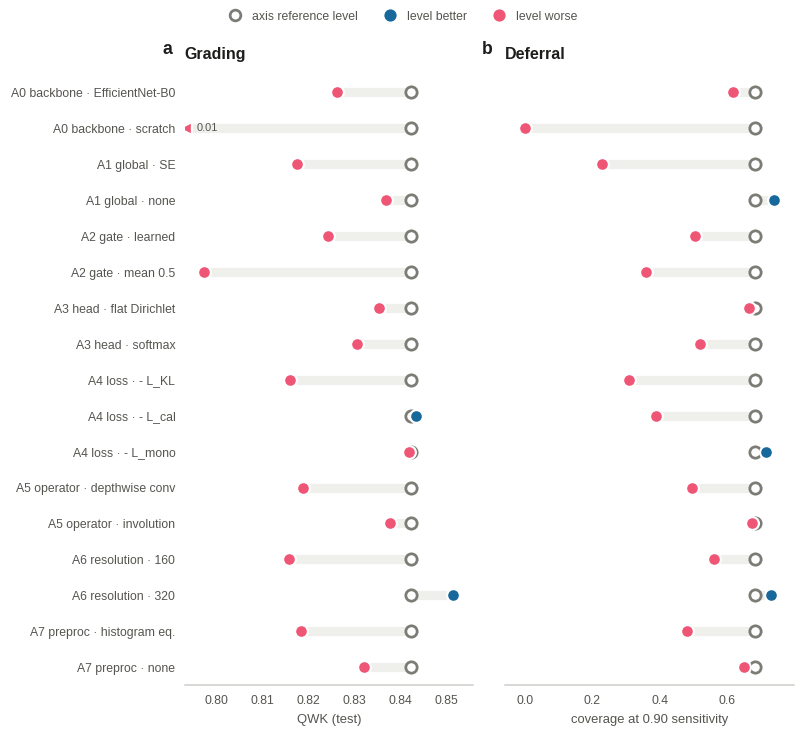

'/content/drive/MyDrive/EvIA_Knee/results/fig_ablation.png'

In [ ]:
rows = []
for axis, ref in REF_LEVEL.items():
    sub = ABLDF[ABLDF.axis == axis]
    if ref not in set(sub.tag):
        continue
    r = sub[sub.tag == ref]
    for lvl in sub.tag.unique():
        if lvl == ref:
            continue
        l = sub[sub.tag == lvl]
        name = axis.split("_", 1)[0] + " " + axis.split("_", 1)[1]
        rows.append(dict(label=f"{name} · {lvl}", ref_q=r.qwk.mean(), q=l.qwk.mean(),
                         ref_c=r.cov90_targeted.mean(), c=l.cov90_targeted.mean()))
DB = pd.DataFrame(rows)

def direction(new, ref):
    return [V.BETTER if n >= o else V.WORSE for n, o in zip(new, ref)]

fig, ax = V.figure(1, 2, width=7.2, height=0.3 * len(DB) + 1.5)
hs = V.dumbbell(ax[0], DB.label, DB.ref_q, DB.q, colors_b=direction(DB.q, DB.ref_q),
                name_a="axis reference level", xlabel="QWK (test)",
                xlim=V.robust_xlim(np.r_[DB.ref_q, DB.q]))   # far outliers drawn at the edge
ax[0].set_title("Grading")
V.dumbbell(ax[1], [""] * len(DB), DB.ref_c, DB.c, colors_b=direction(DB.c, DB.ref_c),
           xlabel="coverage at 0.90 sensitivity", xlim=V.robust_xlim(np.r_[DB.ref_c, DB.c]))
ax[1].set_title("Deferral")
fig.legend(handles=hs + [V.swatch(V.BETTER, "level better"), V.swatch(V.WORSE, "level worse")],
           loc="outside upper center", ncol=3, frameon=False)
V.panel_letters(ax)
V.save(fig, "fig_ablation", CFG.out_dir)